In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

# Load training data
X_train = pd.read_csv(
    "/content/csvTrainImages 60k x 784.csv", header=None
).values

y_train = pd.read_csv(
    "/content/csvTrainLabel 60k x 1.csv", header=None
).values.ravel()

# Load testing data
X_test = pd.read_csv(
    "/content/csvTestImages 10k x 784.csv", header=None
).values

y_test = pd.read_csv(
    "/content/csvTestLabel 10k x 1.csv", header=None
).values.ravel()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 784)
Training labels: (60000,)
Testing images: (10000, 784)
Testing labels: (10000,)


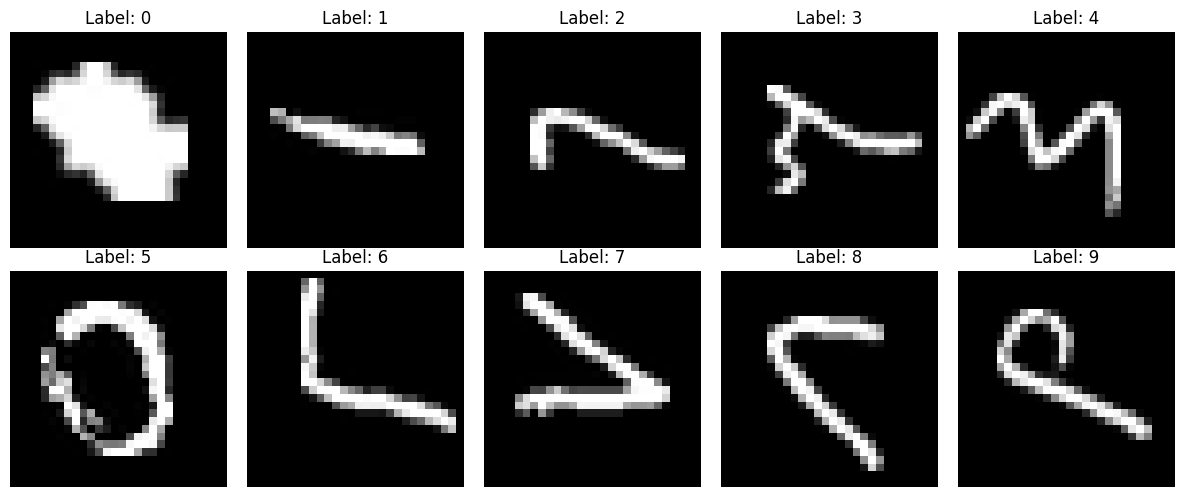

In [2]:

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Convert the 784-pixel row into a 28 x 28 image
    image = X_train[i].reshape(28, 28)

    plt.imshow(image, cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [3]:

np.random.seed(42)

sample_indices = np.random.choice(
    len(X_train), size=5000, replace=False
)

X_train = X_train[sample_indices]
y_train = y_train[sample_indices]

print("Sampled training images:", X_train.shape)


Sampled training images: (5000, 784)


In [4]:

X_train = X_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
X_test = X_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())


Training shape: (5000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


In [5]:

n_classes = len(np.unique(y_train))

model = Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(n_classes, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)


Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8811 - loss: 0.4351 - val_accuracy: 0.9600 - val_loss: 0.1050
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9707 - loss: 0.1048 - val_accuracy: 0.9800 - val_loss: 0.0874
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.9844 - loss: 0.0609 - val_accuracy: 0.9820 - val_loss: 0.0901
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9853 - loss: 0.0474 - val_accuracy: 0.9840 - val_loss: 0.0629
Epoch 5/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9880 - loss: 0.0394 - val_accuracy: 0.9860 - val_loss: 0.0324


In [7]:

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9819 - loss: 0.0584
Test Loss: 0.0584
Test Accuracy: 98.19%


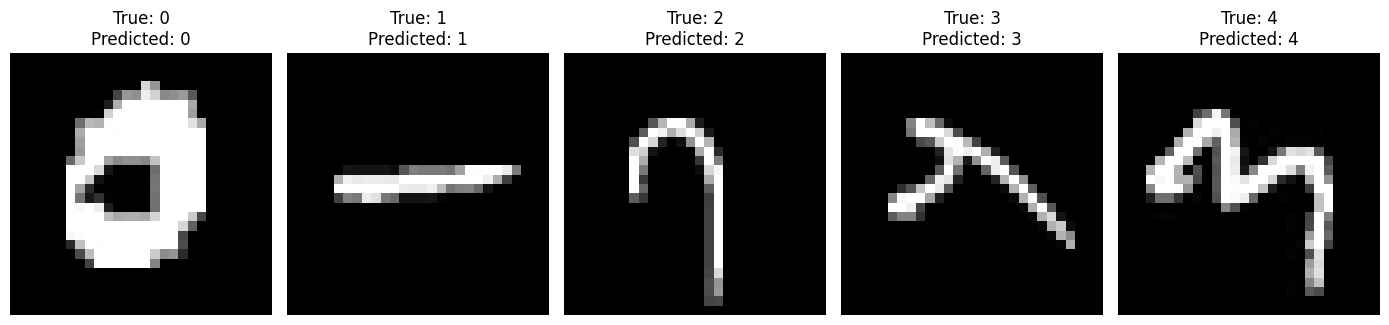

In [8]:

predictions = model.predict(X_test[:5], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(14, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    plt.title(
        f"True: {y_test[i]}\nPredicted: {predicted_labels[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()
